# TAHAP 4 - PENGAYAAN (AUGMENTASI) DATA

Varian dibuat hanya dengan operasi BKPM:

| Jenis | Varian | Operasi (Acara) | Label |
|---|---|---|---|
| Fotometrik | `cerah`, `gelap` | F + k (11) | tetap |
| Fotometrik | `kontras` | imadjust (11) | tetap |
| Fotometrik | `histeq` | histogram equalization (12) | tetap |
| Fotometrik | `gaussian` | imgaussfilt (28) | tetap |
| Fotometrik | `gerak` | konvolusi kernel garis = blur gerak kamera (13-14) | tetap |
| Geometrik | `flip_h` | flip horizontal (8) | dihitung ulang dari mask yang ikut ditransformasi |
| Geometrik | `crop` | crop acak 78-92% (15) | dihitung ulang; objek terpotong < 40% luas dibuang |

Blur gerak dipertahankan karena rompi dipakai sambil berjalan.

Jumlah varian per gambar mengikuti `TARGET`: kelas dengan foto sedikit mendapat varian lebih banyak (maksimum `MAKS_VARIAN`), supaya jumlah gambar antar kelas lebih seimbang. Foto asli selalu ikut. Nama varian: `<nama>__<varian>.jpg`; bagian sebelum `__` dipakai tahap 6 sebagai kunci kelompok.

Letakkan notebook ini di `notebooks/`; modul pendukung ada di `scripts/`.

## 1. Setup dan import

In [9]:

import sys, os
from pathlib import Path

# Menentukan lokasi folder proyek dan scripts
ROOT_PROYEK = Path.cwd().resolve()
SCRIPTS = ROOT_PROYEK.parent / "scripts"

if not SCRIPTS.is_dir():
    SCRIPTS = ROOT_PROYEK / "scripts"

if not SCRIPTS.is_dir():
    raise FileNotFoundError("Folder scripts tidak ditemukan!")

sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import math, random, zlib
from collections import defaultdict

import cv2
import numpy as np
from IPython.display import Image, display

# Import modul proyek
import bkpm
from config import CLASSES, D_AUG, D_LABEL, D_SEG, ROOT
from util import baca_csv, baca_gambar, bersihkan, log, simpan_gambar, tabel, tulis_csv
from yolo_util import baca_label_seg, gambar_berlabel, instans_ke_polygon, tulis_label

TAHAP = "04_pengayaan"

print("Folder proyek :", ROOT)
print("Folder scripts:", SCRIPTS)
print("BKPM tersedia :", (SCRIPTS / "bkpm.py").exists())
print("Input label   :", D_LABEL / "laporan_labelling.csv", "| ada:", (D_LABEL / "laporan_labelling.csv").exists())
print("Folder hasil  :", D_AUG)

Folder proyek : C:\Projek\vestcare-dataset
Folder scripts: C:\Projek\vestcare-dataset\scripts
BKPM tersedia : True
Input label   : C:\Projek\vestcare-dataset\hasil\03_labelling\laporan_labelling.csv | ada: True
Folder hasil  : C:\Projek\vestcare-dataset\hasil\04_pengayaan


## 2. Parameter

Setara argumen CLI `--target` dan `--maks-varian`.

In [10]:
TARGET = 450        # target jumlah gambar per kelas (asli + varian)
MAKS_VARIAN = 7     # maksimum varian per foto asli

POOL = ["flip_h", "cerah", "gerak", "crop", "gelap", "histeq", "gaussian", "kontras"]
print("Target per kelas:", TARGET, "| maks varian per foto:", MAKS_VARIAN)
print("Pool varian     :", POOL)

Target per kelas: 450 | maks varian per foto: 7
Pool varian     : ['flip_h', 'cerah', 'gerak', 'crop', 'gelap', 'histeq', 'gaussian', 'kontras']


## 3. Fungsi varian

- `rng_untuk` : pengacak deterministik per (foto, varian), jadi hasil selalu sama bila diulang
- `varian_foto` : operasi fotometrik (label tetap)
- `varian_geometri` : operasi geometrik; gambar dan mask ditransformasi bersama

In [11]:
def rng_untuk(nama, varian):
    return random.Random(zlib.crc32(f"{nama}|{varian}".encode()))


def varian_foto(img, v, rng):
    if v == "cerah":
        return bkpm.brightness(img, rng.randint(35, 60))
    if v == "gelap":
        return bkpm.brightness(img, -rng.randint(35, 60))
    if v == "kontras":
        return bkpm.enhance_warna(img, "imadjust")
    if v == "histeq":
        return bkpm.enhance_warna(img, "histeq")
    if v == "gaussian":
        return bkpm.imgaussfilt(img, rng.uniform(1.2, 2.2))
    if v == "gerak":
        arah = rng.choice([(-5, 5), (85, 95), (30, 60)])
        k = bkpm.kernel_gerak(rng.randint(9, 17), rng.uniform(*arah))
        return bkpm.konvolusi(img, k)
    raise ValueError(v)


def varian_geometri(img, lab, v, rng):
    h, w = lab.shape
    if v == "flip_h":
        return np.ascontiguousarray(img[:, ::-1]), np.ascontiguousarray(lab[:, ::-1]), 1.0
    # crop: ambil 78-92% gambar dari posisi acak lalu kembalikan ke ukuran semula
    f = rng.uniform(0.78, 0.92)
    cw, ch = int(w * f), int(h * f)
    x0, y0 = rng.randint(0, w - cw), rng.randint(0, h - ch)
    ci, cl = img[y0:y0 + ch, x0:x0 + cw], lab[y0:y0 + ch, x0:x0 + cw]
    return (cv2.resize(ci, (w, h), interpolation=cv2.INTER_LINEAR),
            cv2.resize(cl, (w, h), interpolation=cv2.INTER_NEAREST), f * f)


def buat_varian(img, lab, stem, v):
    """Satu varian lengkap: (citra, polygon). polygon kosong = varian dibuang (mis. crop memotong semua objek)."""
    rng = rng_untuk(stem, v)
    if v in ("flip_h", "crop"):
        im2, lab2, skala = varian_geometri(img, lab, v, rng)
        polys = instans_ke_polygon(lab2)
        if v == "crop":      # buang objek yang terpotong sehingga tersisa < 40% luas semula
            asli = {i: int((lab == i).sum()) for i in range(1, int(lab.max()) + 1)}
            polys = [(i, p) for i, p in polys if (lab2 == i).sum() * skala >= 0.4 * asli.get(i, 1)]
        return im2, polys
    return varian_foto(img, v, rng), instans_ke_polygon(lab)


def tampil(img, maks=1100):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))

print("fungsi siap")

fungsi siap


## 4. Baca hasil labelling dan rencana varian per kelas

Jumlah varian per foto = `min(MAKS_VARIAN, ceil(TARGET / jumlah_foto) - 1)`. Kelas yang fotonya sedikit mendapat varian lebih banyak.

In [12]:
lap = baca_csv(D_LABEL / "laporan_labelling.csv")
if not lap:
    raise SystemExit("laporan_labelling.csv kosong: jalankan notebook 03_labelling dulu")
per_kelas = defaultdict(list)
for r in lap:
    per_kelas[r["kelas"]].append(r)

rencana = []
for kelas in CLASSES:
    n = len(per_kelas.get(kelas, []))
    if n:
        n_var = min(MAKS_VARIAN, max(0, math.ceil(TARGET / n) - 1))
        rencana.append({"kelas": kelas, "foto_asli": n, "varian_per_foto": n_var, "perkiraan_total": n * (1 + n_var),
                        "tercapai_target": "ya" if n * (1 + n_var) >= TARGET else "belum (batas MAKS_VARIAN)"})
    else:
        rencana.append({"kelas": kelas, "foto_asli": 0, "varian_per_foto": 0, "perkiraan_total": 0, "tercapai_target": "-"})
tabel("Rencana pengayaan", rencana, ["kelas", "foto_asli", "varian_per_foto", "perkiraan_total", "tercapai_target"])


Rencana pengayaan
kelas   foto_asli  varian_per_foto  perkiraan_total  tercapai_target
pohon   187        2                561              ya             
lubang  317        1                634              ya             
orang   123        3                492              ya             
motor   220        2                660              ya             
mobil   199        2                597              ya             


## 5. Demo semua jenis varian pada satu gambar

Tiap panel menampilkan hasil satu varian beserta polygon labelnya (polygon dihitung ulang dari mask untuk `flip_h` dan `crop`; yang fotometrik memakai polygon asli).

Contoh: pohon_primer-pohon-1.jpg (pohon) | ukuran 312 x 416 | objek asli: 1


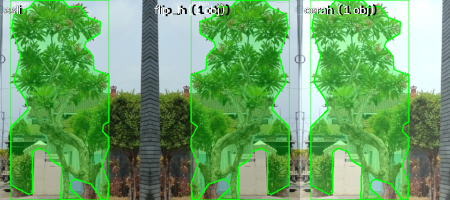

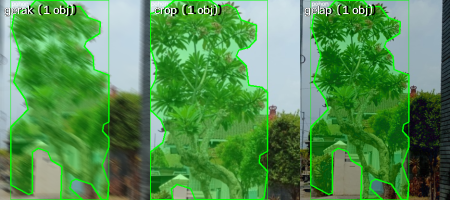

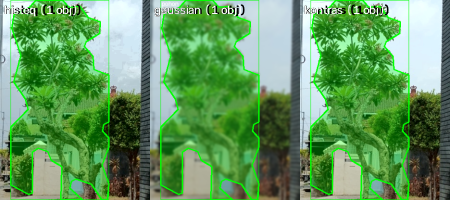

In [13]:
contoh = lap[0]
nama = contoh["file"]
stem = nama.rsplit(".", 1)[0]
kelas_c = contoh["kelas"]
img = baca_gambar(D_LABEL / "images" / nama)
lab = cv2.imdecode(np.fromfile(str(D_SEG / "mask" / kelas_c / f"{stem}.png"), np.uint8), cv2.IMREAD_UNCHANGED)
print("Contoh:", nama, f"({kelas_c})", "| ukuran", img.shape[1], "x", img.shape[0], "| objek asli:", int(lab.max()))

galeri = [(gambar_berlabel(img, instans_ke_polygon(lab), kelas_c), "asli")]
for v in POOL:
    im2, polys = buat_varian(img, lab, stem, v)
    ket = f"{v} ({len(polys)} obj)" if polys else f"{v} DIBUANG"
    galeri.append((gambar_berlabel(im2, polys, kelas_c) if polys else im2, ket))
tampil_baris(galeri, tinggi=200, per_baris=3)

## 6. Perbandingan nilai piksel varian fotometrik

Rata-rata keabuan dan ketajaman (varians Laplacian) tiap varian terhadap foto asli: memastikan tiap operasi benar-benar mengubah citra.

In [14]:
def ukur(im):
    g = bkpm.rgb2gray(im)
    return float(g.mean()), float(cv2.Laplacian(g, cv2.CV_64F).var())

m0, t0 = ukur(img)
print(f"{'varian':10s} {'rata abu':>9s} {'selisih':>8s} {'ketajaman':>10s} {'rasio':>7s}")
print(f"{'asli':10s} {m0:9.1f} {0:8.1f} {t0:10.1f} {1:7.2f}")
for v in ("cerah", "gelap", "kontras", "histeq", "gaussian", "gerak"):
    m, t = ukur(varian_foto(img, v, rng_untuk(stem, v)))
    print(f"{v:10s} {m:9.1f} {m - m0:+8.1f} {t:10.1f} {t / t0 if t0 else 0:7.2f}")

varian      rata abu  selisih  ketajaman   rasio
asli           120.6      0.0     1791.9    1.00
cerah          165.5    +44.9     1778.1    0.99
gelap           83.3    -37.3     1679.9    0.94
kontras        128.0     +7.4     2796.1    1.56
histeq         121.7     +1.1     2921.6    1.63
gaussian       120.6     +0.0       10.9    0.01
gerak          120.6     -0.0      130.4    0.07


## 7. Proses pengayaan seluruh gambar

Untuk tiap foto asli: salin asli (gambar + label), lalu buat varian sesuai rencana. Varian yang kehilangan semua objek (mis. `crop`) dilewati dan dicatat.

> Sel ini **menghapus dan membuat ulang** `hasil/04_pengayaan/`.

In [15]:
bersihkan(D_AUG)
(D_AUG / "images").mkdir(parents=True, exist_ok=True)
for sub in ("labels_seg", "labels_det"):
    (D_AUG / sub).mkdir(parents=True, exist_ok=True)

manifest, ring = [], []
dibuang = defaultdict(int)      # (kelas, varian) -> jumlah varian yang dibuang karena tanpa objek

for kelas in CLASSES:
    daftar = per_kelas.get(kelas, [])
    if not daftar:
        continue
    n_var = min(MAKS_VARIAN, max(0, math.ceil(TARGET / len(daftar)) - 1))
    kid = CLASSES.index(kelas)
    for idx, r in enumerate(daftar):
        nama = r["file"]
        stem = nama.rsplit(".", 1)[0]
        img = baca_gambar(D_LABEL / "images" / nama)
        lab = cv2.imdecode(np.fromfile(str(D_SEG / "mask" / kelas / f"{stem}.png"), np.uint8), cv2.IMREAD_UNCHANGED)
        h, w = img.shape[:2]
        simpan_gambar(D_AUG / "images" / nama, img, 95)
        for sub in ("labels_seg", "labels_det"):
            (D_AUG / sub / f"{stem}.txt").write_text((D_LABEL / sub / f"{stem}.txt").read_text())
        manifest.append({"file": nama, "sumber": stem, "kelas": kelas, "varian": "asli", "lebar": w, "tinggi": h})
        urut = [POOL[(idx + j) % len(POOL)] for j in range(len(POOL))][:n_var]
        for v in urut:
            im2, polys = buat_varian(img, lab, stem, v)
            if not polys:
                dibuang[(kelas, v)] += 1
                continue
            nv = f"{stem}__{v}"
            simpan_gambar(D_AUG / "images" / f"{nv}.jpg", im2, 95)
            tulis_label(D_AUG / "labels_seg" / f"{nv}.txt", D_AUG / "labels_det" / f"{nv}.txt", kid, polys, w, h)
            manifest.append({"file": f"{nv}.jpg", "sumber": stem, "kelas": kelas, "varian": v, "lebar": w, "tinggi": h})
    n_all = sum(1 for m in manifest if m["kelas"] == kelas)
    ring.append({"kelas": kelas, "foto_asli": len(daftar), "varian_per_foto": n_var, "total_gambar": n_all})
    log(TAHAP, f"{kelas}: {len(daftar)} asli -> {n_all} gambar")

print("\nVarian dibuang (tanpa objek tersisa):", dict(dibuang) or "tidak ada")

[04_pengayaan] pohon: 187 asli -> 561 gambar
[04_pengayaan] lubang: 317 asli -> 634 gambar
[04_pengayaan] orang: 123 asli -> 492 gambar
[04_pengayaan] motor: 220 asli -> 660 gambar
[04_pengayaan] mobil: 199 asli -> 597 gambar

Varian dibuang (tanpa objek tersisa): tidak ada


## 8. Simpan manifest dan ringkasan

In [16]:
tulis_csv(D_AUG / "manifest_pengayaan.csv", manifest, ["file", "sumber", "kelas", "varian", "lebar", "tinggi"])
tot = {"kelas": "TOTAL", "foto_asli": sum(r["foto_asli"] for r in ring), "varian_per_foto": "-",
       "total_gambar": sum(r["total_gambar"] for r in ring)}
tabel("Ringkasan pengayaan", ring + [tot], ["kelas", "foto_asli", "varian_per_foto", "total_gambar"])
log(TAHAP, f"manifest -> {D_AUG / 'manifest_pengayaan.csv'} ({len(manifest)} baris)")


Ringkasan pengayaan
kelas   foto_asli  varian_per_foto  total_gambar
pohon   187        2                561         
lubang  317        1                634         
orang   123        3                492         
motor   220        2                660         
mobil   199        2                597         
TOTAL   1046       -                2944        
[04_pengayaan] manifest -> C:\Projek\vestcare-dataset\hasil\04_pengayaan\manifest_pengayaan.csv (2944 baris)


## 9. Sebaran varian per kelas

Jumlah gambar tiap jenis varian per kelas. Menunjukkan keseimbangan antar kelas dan antar jenis varian.

In [17]:
jenis = ["asli"] + POOL
print(f"{'kelas':8s} " + " ".join(f"{j:>8s}" for j in jenis) + f" {'total':>7s}")
for k in CLASSES:
    rr = [m for m in manifest if m["kelas"] == k]
    if rr:
        print(f"{k:8s} " + " ".join(f"{sum(m['varian'] == j for m in rr):8d}" for j in jenis) + f" {len(rr):7d}")

kelas        asli   flip_h    cerah    gerak     crop    gelap   histeq gaussian  kontras   total
pohon         187       47       48       48       47       46       46       46       46     561
lubang        317       40       40       40       40       40       39       39       39     634
orang         123       46       47       48       47       46       45       45       45     492
motor         220       55       56       56       56       55       54       54       54     660
mobil         199       49       50       50       50       50       50       50       49     597


## 10. Pemeriksaan konsistensi

- setiap gambar di manifest punya file gambar dan label `seg` + `det`
- jumlah baris `seg` = `det`
- koordinat label di rentang 0-1
- tidak ada gambar tanpa objek

In [18]:
masalah = []
for m in manifest:
    stem = m["file"].rsplit(".", 1)[0]
    p_img = D_AUG / "images" / m["file"]
    p_seg, p_det = D_AUG / "labels_seg" / f"{stem}.txt", D_AUG / "labels_det" / f"{stem}.txt"
    if not (p_img.exists() and p_seg.exists() and p_det.exists()):
        masalah.append((m["file"], "file hilang"))
        continue
    seg = [s for s in p_seg.read_text().split("\n") if s.strip()]
    det = [s for s in p_det.read_text().split("\n") if s.strip()]
    if not seg:
        masalah.append((m["file"], "tanpa objek"))
    if len(seg) != len(det):
        masalah.append((m["file"], "baris seg != det"))
    for s in seg + det:
        v = np.array(s.split()[1:], float)
        if v.size and (v.min() < 0 or v.max() > 1):
            masalah.append((m["file"], "koordinat di luar 0-1"))
            break
n_img = len(list((D_AUG / "images").glob("*.jpg")))
print(f"manifest={len(manifest)}  images={n_img}  labels_seg={len(list((D_AUG / 'labels_seg').glob('*.txt')))}  labels_det={len(list((D_AUG / 'labels_det').glob('*.txt')))}")
print("Masalah:", len(masalah))
for x in masalah[:20]:
    print("  ", x)
if not masalah:
    print("Semua gambar dan label konsisten.")

manifest=2944  images=2944  labels_seg=2944  labels_det=2944
Masalah: 0
Semua gambar dan label konsisten.


## 11. Galeri hasil pengayaan

Satu foto asli per kelas beserta varian-variannya, lengkap dengan polygon label.


== pohon: pohon_primer-pohon-1 (3 gambar) ==


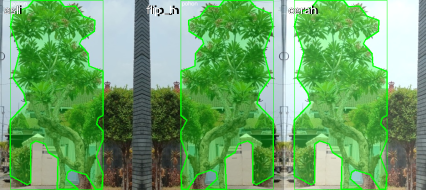


== lubang: lubang_1 (2 gambar) ==


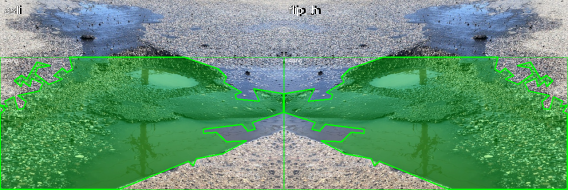


== orang: orang_orang_1 (4 gambar) ==


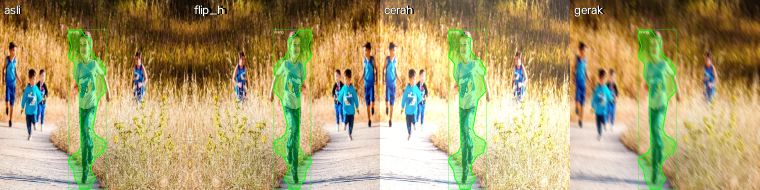


== motor: motor_motor_IMG_00556 (3 gambar) ==


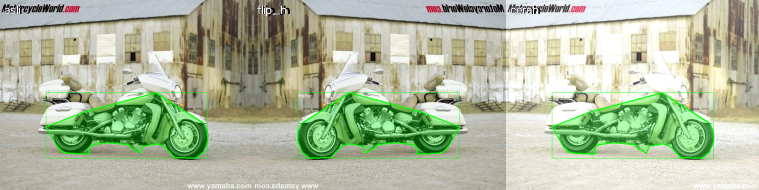


== mobil: mobil_IMG_4167 (3 gambar) ==


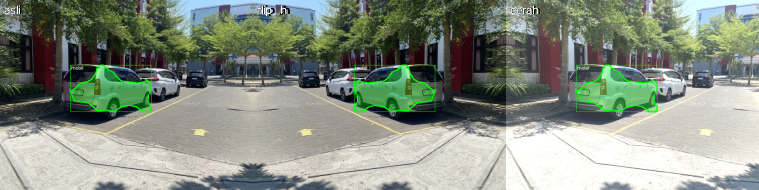

In [19]:
for k in CLASSES:
    rr = [m for m in manifest if m["kelas"] == k and m["varian"] == "asli"]
    if not rr:
        continue
    sumber = rr[0]["sumber"]
    anggota = [m for m in manifest if m["sumber"] == sumber][:8]
    print(f"\n== {k}: {sumber} ({len(anggota)} gambar) ==")
    galeri = []
    for m in anggota:
        stem = m["file"].rsplit(".", 1)[0]
        im = baca_gambar(D_AUG / "images" / m["file"])
        polys = [(i, rel * [im.shape[1], im.shape[0]]) for i, (_, rel) in enumerate(baca_label_seg(D_AUG / "labels_seg" / f"{stem}.txt"), 1)]
        galeri.append((gambar_berlabel(im, polys, k), m["varian"]))
    tampil_baris(galeri, tinggi=190, per_baris=4)

## 12. Pemeriksaan akhir

In [20]:
log(TAHAP, f"selesai -> {D_AUG}")
print(f"Total gambar : {len(manifest)}")
print("Per kelas    :", {k: sum(m['kelas'] == k for m in manifest) for k in CLASSES})
print("\nLanjut ke notebook 05_ekstraksi_fitur.ipynb")

[04_pengayaan] selesai -> C:\Projek\vestcare-dataset\hasil\04_pengayaan
Total gambar : 2944
Per kelas    : {'pohon': 561, 'lubang': 634, 'orang': 492, 'motor': 660, 'mobil': 597}

Lanjut ke notebook 05_ekstraksi_fitur.ipynb
